# 01 — Is the business growing?

**Leadership question:** Is Olist growing, and how fast?

## KPI definitions
| Decision | Choice | Why |
|---|---|---|
| Headline KPI | Monthly revenue (GMV) | Revenue pays the bills |
| Supporting KPIs | Orders, active customers, average order value | Explain *why* revenue moves (KPI tree) |
| Revenue | Sum of item prices, excluding freight | Freight is shipping cost, not sales of goods |
| Orders counted | All except `canceled` and `unavailable` | Those never became real sales; in-progress orders are kept |
| Customers | Counted by `customer_unique_id` | `customer_id` is created per order |
| Time grain | Month of purchase | Daily is too noisy for leadership |
| Window | Jan 2017 – Aug 2018 | Earlier months are a test phase, later ones are cut off by the export |

In [2]:
from pathlib import Path
import duckdb

DB_PATH = Path("../data/olist.duckdb")
con = duckdb.connect(str(DB_PATH), read_only=True)

con.sql("SELECT COUNT(*) AS orders FROM raw.orders")

ordersBIGINT
99441


In [3]:
query = """
WITH order_revenue AS (          -- step 1: item grain -> order grain
    SELECT order_id, SUM(price) AS revenue
    FROM raw.order_items
    GROUP BY order_id
),
valid_orders AS (                -- step 2: one row per valid order
    SELECT o.order_id,
           DATE_TRUNC('month', o.order_purchase_timestamp) AS month,
           c.customer_unique_id,
           COALESCE(r.revenue, 0) AS revenue
    FROM raw.orders o
    JOIN raw.customers c      ON o.customer_id = c.customer_id
    LEFT JOIN order_revenue r ON o.order_id = r.order_id
    WHERE o.order_status NOT IN ('canceled', 'unavailable')
      AND o.order_purchase_timestamp >= '2017-01-01'
      AND o.order_purchase_timestamp <  '2018-09-01'
)
SELECT month,                    -- step 3: order grain -> month grain
       SUM(revenue)                       AS revenue,
       COUNT(*)                           AS orders,
       COUNT(DISTINCT customer_unique_id) AS active_customers,
       SUM(revenue) / COUNT(*)            AS avg_order_value
FROM valid_orders
GROUP BY month
ORDER BY month
"""
monthly = con.sql(query).df()
monthly

,month,revenue,orders,active_customers,avg_order_value
0,2017-01-01,120098.27,787,753,152.602630
1,2017-02-01,244959.35,1718,1693,142.584022
2,2017-03-01,368341.32,2617,2577,140.749454
3,2017-04-01,353842.98,2377,2345,148.861161
4,2017-05-01,503159.19,3640,3569,138.230547
5,2017-06-01,429916.61,3205,3142,134.139348
6,2017-07-01,492287.30,3946,3872,124.756031
7,2017-08-01,568245.79,4272,4191,133.016337
8,2017-09-01,621415.91,4227,4154,147.011098
9,2017-10-01,660179.62,4547,4481,145.190152


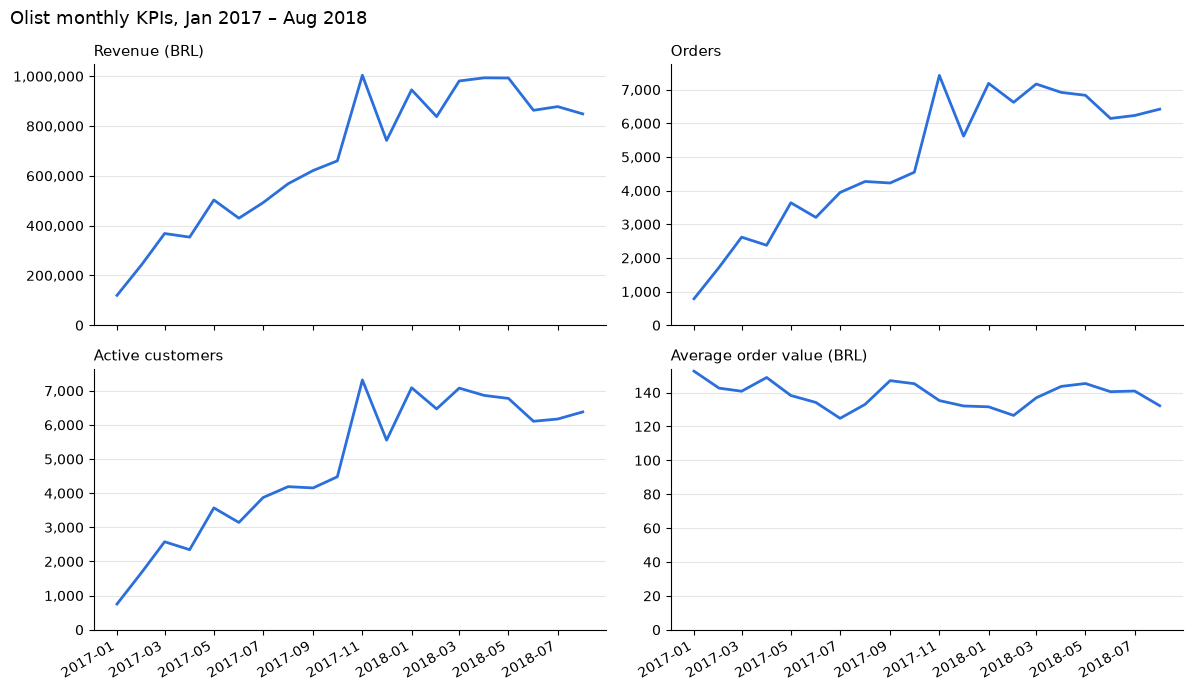

In [4]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

kpis = [
    ("revenue", "Revenue (BRL)"),
    ("orders", "Orders"),
    ("active_customers", "Active customers"),
    ("avg_order_value", "Average order value (BRL)"),
]

fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
for ax, (col, title) in zip(axes.flat, kpis):
    ax.plot(monthly["month"], monthly[col], color="#2a6fdb", linewidth=2)
    ax.set_title(title, loc="left", fontsize=11)
    ax.set_ylim(bottom=0)
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.grid(axis="y", color="#e5e5e5")
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle("Olist monthly KPIs, Jan 2017 – Aug 2018", x=0.01, ha="left", fontsize=13)
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

## Findings
- **Yes, Olist grew strongly through 2017.** Monthly revenue, orders and active customers all rose several-fold from January to late 2017.
- **Growth was driven by volume, not basket size.** Revenue, orders and customers move together, while average order value stayed flat to slightly declining (the high early values rest on few orders and are less reliable).
- **Growth plateaued in 2018.** Orders held at roughly 6,200–7,300 per month from January to August 2018.

**Next questions:** What caused the plateau? Do customers return (Q4)? Which categories and sellers drive revenue (Q2)?